<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Исследовательский-анализ-данных" data-toc-modified-id="Исследовательский-анализ-данных-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Исследовательский анализ данных</a></span></li><li><span><a href="#Обучение-модели" data-toc-modified-id="Обучение-модели-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Обучение модели</a></span></li><li><span><a href="#Анализ-обученной-модели" data-toc-modified-id="Анализ-обученной-модели-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Анализ обученной модели</a></span></li></ul></div>

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Исследовательский-анализ-данных" data-toc-modified-id="Исследовательский-анализ-данных-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Исследовательский анализ данных</a></span></li><li><span><a href="#Обучение-модели" data-toc-modified-id="Обучение-модели-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Обучение модели</a></span></li><li><span><a href="#Анализ-обученной-модели" data-toc-modified-id="Анализ-обученной-модели-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Анализ обученной модели</a></span></li><li><span>

# Определение возраста покупателей


Сетевой супермаркет «Хлеб-Соль» внедряет систему компьютерного зрения для обработки фотографий покупателей. Фотофиксация в прикассовой зоне поможет определять возраст клиентов, чтобы:
 
- Анализировать покупки и предлагать товары, которые могут заинтересовать покупателей этой возрастной группы;
- Контролировать добросовестность кассиров при продаже алкоголя.
 
Текущей задачей является построение модели, которая по фотографии определит приблизительный возраст человека. В нашем распоряжении набор фотографий людей с указанием их возраста.


In [1]:
#Загрузим все необходимые библиотеки
import os

import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.optimizers import Adam

## Исследовательский анализ данных

Далее проведём исследовательский анализ данных

In [2]:
#Загрузим данные
pth1 = 'labels.csv'
pth2 = '/datasets/faces/labels.csv'
pth_files1 = ''
pth_files2 = '/datasets/faces/final_files/'

if os.path.exists(pth1):
    labels = pd.read_csv(pth1)
    train_datagen = ImageDataGenerator(rescale=1./255)
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=pth_files1,
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345) 
elif os.path.exists(pth2):
    labels = pd.read_csv(pth2)
    train_datagen = ImageDataGenerator(rescale=1./255)
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=pth_files2,
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        seed=12345) 
else:
    print('Something is wrong')
    

Found 7591 validated image filenames.


In [3]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [4]:
labels.head()

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


In [5]:
print(f'Количество дубликатов: {labels.duplicated().sum()}, количество пустых строк: {labels.isna().sum().sum()}')

Количество дубликатов: 0, количество пустых строк: 0


В датафрейме реального возраста людей имеется всего 7591 события. Все возраста имеются размерность int. Дубликаты или пустые строчки в датафреме отсуствуют.

In [6]:
features, target = next(train_gen_flow)
print(f'Размер и размерность одного батча с данными: {features.shape}') 

Размер и размерность одного батча с данными: (32, 224, 224, 3)


Видим что картинки у нас получились по 224 на 224 пикселя в трех цветах.
Нарисуем распределение возраста в пером батче данных.

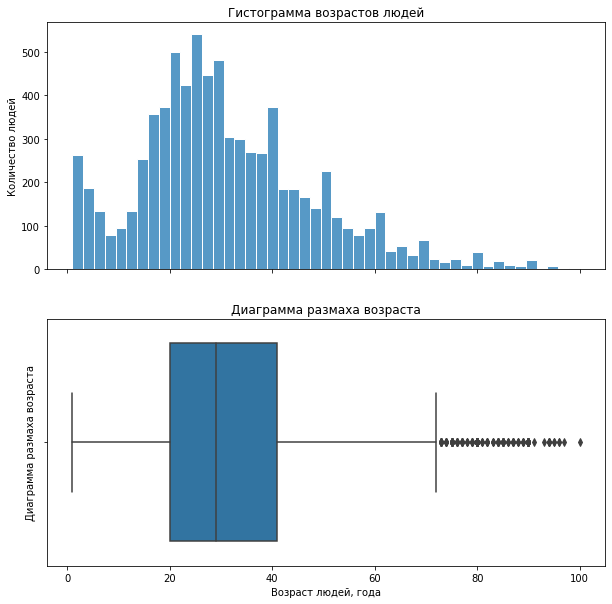

In [7]:
fig, ax=plt.subplots(nrows=2, ncols=1, figsize=(10, 10), sharex=True)
sns.set_style("whitegrid")
sns.histplot(x=labels['real_age'], ax = ax[0]);
ax[0].set(ylabel='Количество людей', xlabel='Возраст людей, года', title='Гистограмма возрастов людей');
sns.boxplot(x=labels['real_age'], ax = ax[1]);
ax[1].set(xlabel='Возраст людей, года', ylabel='Диаграмма размаха возраста', title='Диаграмма размаха возраста');

Выше видно, что возраст варьирируется в очень широких пределах вплоть 100 лет. Большинство людей в датасете - молодые люди возрастом от 15 до 45 лет и от 0 до 10. Медианное значение возраста находится на уровне 30 лет. Большая часть людей находится в диапазоне до 70.

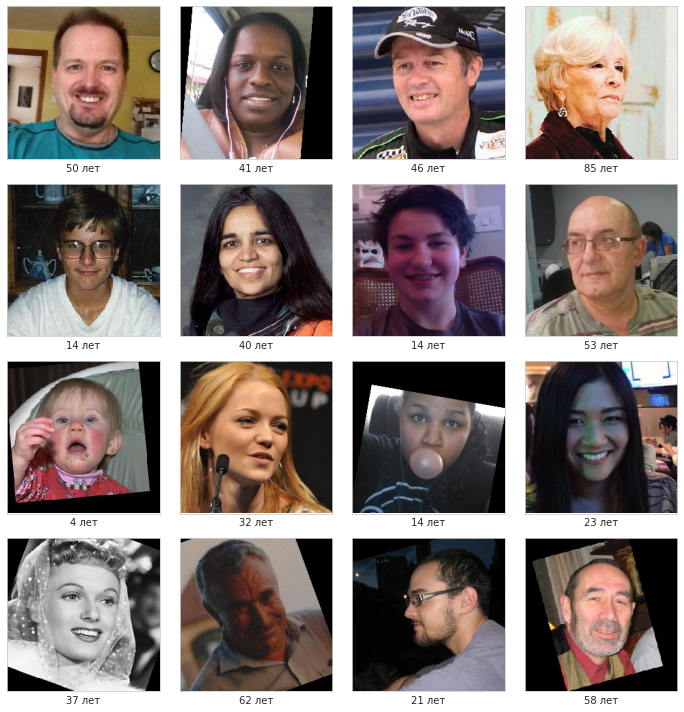

In [8]:
fig = plt.figure(figsize=(10,10))
for i in range(16):
    ax=fig.add_subplot(4, 4, i+1)
    plt.imshow(features[i])
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()
    ax.set(xlabel=str(target[i]) + ' лет');

На 16 картинках выше видно, что все фотографии сильно различаются как по качеству картинки и по цветовой палитре, так и по формату съёмки. 

В работе используется датасет с 7591 событием. На каждое событие имеется фотография человека и его реальный возраст.
Целевой признак, возраст человека, распределен от 0 до 100 лет с медианным значением около 30. Наибольшая часть фотографий - молодые люди возрастом от 15 до 45 лет. Сами фотографии различаются по сравнению друг с другом. Фотографии сделаны под разными углами, разной кадаровкой снимка. Они отличается цветом (некоторые фотографии чёрно-белые, некоторые цветные), качеством и детализацией снимка. На фотографии люди смотрят в разные стороны (кто в камеру, кто в сторону), изображают различные эмоции и мимику. Также на некоторых фотографиях присутствуют постороние предметы. Все вышесказанные моменты могут затруднить процесс прогнозирования возраста нейросетью.

## Обучение модели

Так как у нас стоит задача регрессии, то выходной слой будет состоять из одного нейрона. Обучим модель при помощи метрики MAE, при этом будем использовать в качестве функции потерь MSE.

```python
import pandas as pd
import numpy as np

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.optimizers import Adam


def load_test(path):
    labels = pd.read_csv(path+'labels.csv')
    datagen = ImageDataGenerator(validation_split=0.25, rescale = 1./255)
    test_datagen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path+'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',  
        subset='validation',
        seed=12345)
    return test_datagen_flow


def load_train(path):
    labels = pd.read_csv(path+'labels.csv')
    datagen = ImageDataGenerator(validation_split=0.25, rescale = 1./255, vertical_flip=True, horizontal_flip=True)
    train_datagen_flow = datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path+'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,     
        subset='training',
        class_mode='raw',
        seed=12345) 
    return  train_datagen_flow

def create_model(input_shape):
    backbone = ResNet50(input_shape=input_shape,
                    weights='/datasets/keras_models/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5',
                    include_top=False)
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu')) 
    optimizer = Adam(lr=0.0001)
    model.compile(optimizer=optimizer, loss='mean_squared_error',
                  metrics=['mae']) 
    return model 



def train_model(model, train_data, test_data, batch_size=None, epochs=10,
                    steps_per_epoch=None, validation_steps=None):

    model.fit(train_data,
                validation_data=test_data,
                batch_size=batch_size, epochs=epochs,
                steps_per_epoch=steps_per_epoch,
                validation_steps=validation_steps,
                verbose=2)
    model.summary()
    return model

```

```
Found 5694 validated image filenames.
Found 1897 validated image filenames.
Train for 178 steps, validate for 60 steps
Epoch 1/10
178/178 - 74s - loss: 282.5638 - mae: 12.1912 - val_loss: 872.2303 - val_mae: 24.6730
Epoch 2/10
178/178 - 43s - loss: 106.0409 - mae: 7.7455 - val_loss: 764.0121 - val_mae: 22.6249
Epoch 3/10
178/178 - 43s - loss: 82.4700 - mae: 6.7976 - val_loss: 333.8607 - val_mae: 13.7036
Epoch 4/10
178/178 - 43s - loss: 66.7159 - mae: 6.2328 - val_loss: 128.0437 - val_mae: 8.4160
Epoch 5/10
178/178 - 43s - loss: 54.4278 - mae: 5.6233 - val_loss: 96.4872 - val_mae: 7.4087
Epoch 6/10
178/178 - 43s - loss: 45.5758 - mae: 5.0765 - val_loss: 80.0083 - val_mae: 6.6935
Epoch 7/10
178/178 - 43s - loss: 38.7106 - mae: 4.7675 - val_loss: 86.9658 - val_mae: 7.0956
Epoch 8/10
178/178 - 44s - loss: 33.6894 - mae: 4.4384 - val_loss: 76.4581 - val_mae: 6.5799
Epoch 9/10
178/178 - 44s - loss: 31.0248 - mae: 4.2316 - val_loss: 89.2856 - val_mae: 7.2764
Epoch 10/10
178/178 - 43s - loss: 26.5463 - mae: 3.9319 - val_loss: 78.4474 - val_mae: 6.5293
Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
resnet50 (Model)             (None, 7, 7, 2048)        23587712  
_________________________________________________________________
global_average_pooling2d (Gl (None, 2048)              0         
_________________________________________________________________
dense (Dense)                (None, 1)                 2049      
=================================================================
Total params: 23,589,761
Trainable params: 23,536,641
Non-trainable params: 53,120
_________________________________________________________________
```

## Анализ обученной модели

Модель регрессионной нейронной сети была построена при помощи модели ResNet50 без верхушки, gloval_average_pooling и слоя dense с одним выходным нейроном. Модель была обучена за 10 эпох, каждая из которых обучалась в районе 50 секунд. Метрика MAE на валидационных данных составляет менее 7, для получения лучшей метрики можно увеличить количество эпох или увеличить размер батчей в генераторе.

На выводе работы сети видно, что она немного переобучается на тренировочных данных, слишком много параметром в модели ResNet50 для этой задачи, но несмотря на это, предсказательная способность сети на валидационной выборке в среднем улучшается с каждой эпохой.

# Заключение

Таким образом в работе, была рассмотрена задача по определению возраста человека по фотографии.

На первом шаге были скачаны данные и проведён исследовательский анализ данных. В результате исследования было пронаблюдено, что фотографии варьируется по качеству, цветовой палитре, формату съёмки и самого снимка, также сами люди на фотографиях смотрят в разные стороны и изображают различные эмоции и мимики. В задаче имеется большой размах возрастов людей вплоть до 100 лет, что усложняет работу нейросети.

На втором шаге была построена сама нейронная сеть на основе модели ResNet50 без верхушки с выходом на один нейрон через global_average_pooling и слоя dense с функцией активации relu, чтобы конечный возраст был положительный. Метрикой являлась MAE, а функция потерь MSE.
Модель была обучена на 10 эпохах на всём датасете, в результате работы метрика на валидационной выборке составляет менее требуемых 8.